In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,classification_report
import matplotlib.pyplot as plt

In [3]:
data=pd.read_csv("creditcard.csv")
print(data.shape)

(284807, 31)


In [51]:
x=data.drop('Class',axis=1).values
y=data['Class'].values

In [52]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [53]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [54]:
x_train_normal=x_train[y_train==0]

In [55]:
print("Training Data:",x_train_normal.shape)
print("testing data:",x_test.shape)

Training Data: (227451, 30)
testing data: (56962, 30)


In [56]:
model=tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(x_train_normal.shape[1],)),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(8,activation='relu'),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(x_train_normal.shape[1],activation='linear')
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
              loss='mse',
              metrics=['mae']
             )

In [58]:
history=model.fit(x_train_normal,x_train_normal,epochs=10,batch_size=256,validation_split=0.2,shuffle=True)

Epoch 1/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 0.5495 - mae: 0.4994 - val_loss: 0.4950 - val_mae: 0.4640
Epoch 2/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4654 - mae: 0.4521 - val_loss: 0.4793 - val_mae: 0.4499
Epoch 3/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4552 - mae: 0.4396 - val_loss: 0.4728 - val_mae: 0.4383
Epoch 4/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.4485 - mae: 0.4302 - val_loss: 0.4654 - val_mae: 0.4317
Epoch 5/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.4471 - mae: 0.4266 - val_loss: 0.4644 - val_mae: 0.4274
Epoch 6/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4443 - mae: 0.4220 - val_loss: 0.4600 - val_mae: 0.4225
Epoch 7/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.4422 - mae: 0.4189 - val_loss: 0.4570 - val_mae: 0.4206
Epoch 8/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.4417 - mae: 0.4172 - val_loss: 0.4574 - val_mae: 0.4194
Epoch 9/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/ste

In [59]:

train_pred=model.predict(x_train_normal,verbose=0)
train_error=np.mean(np.square(x_train_normal-train_pred),axis=1)
threshold=np.percentile(train_error,95)
print("reconstruction error threshold:",threshold)

test_pred=model.predict(x_test,verbose=0)
test_error=np.mean(np.square(x_test-test_pred),axis=1)

y_pred=(test_error>threshold).astype(int)

print("Total Fraud Trasactions:",np.sum(y_pred==1))

reconstruction error threshold: 0.9983785781707135
Total Fraud Trasactions: 2989


In [63]:
print("Training Loss:", history.history['loss'])
print("Validation Loss:", history.history['val_loss'])

print("Number of epochs:", len(history.history['loss']))

print("Final Training Loss:", history.history['loss'][-1])
print("Final Validation Loss:", history.history['val_loss'][-1])
print(confusion_matrix(y_test,y_pred))



Training Loss: [0.5495092272758484, 0.4653645157814026, 0.45522814989089966, 0.4485454857349396, 0.4470902681350708, 0.44428056478500366, 0.44222700595855713, 0.4416825771331787, 0.4416029751300812, 0.43909165263175964]
Validation Loss: [0.49499136209487915, 0.47928696870803833, 0.4727865159511566, 0.46544358134269714, 0.464402973651886, 0.4600357115268707, 0.45696693658828735, 0.45735129714012146, 0.45448383688926697, 0.4531407952308655]
Number of epochs: 10
Final Training Loss: 0.43909165263175964
Final Validation Loss: 0.4531407952308655
[[53957  2907]
 [   16    82]]


In [61]:
print(classification_report(y_test,y_pred,zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.84      0.05        98

    accuracy                           0.95     56962
   macro avg       0.51      0.89      0.51     56962
weighted avg       1.00      0.95      0.97     56962



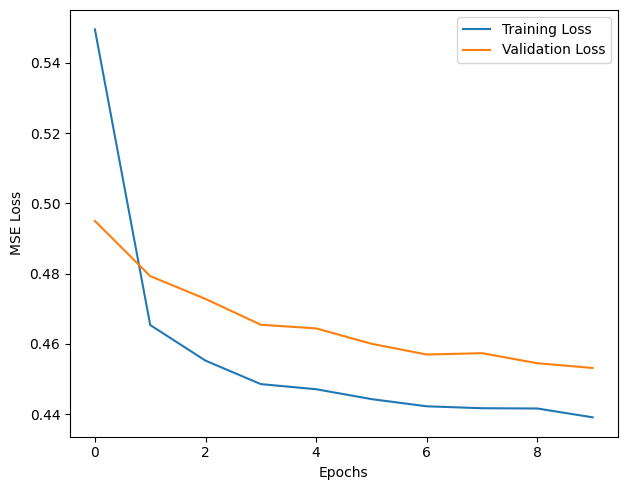

In [62]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)

plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

# Load dataset
data = pd.read_csv("creditcard.csv")
print(data.shape)

x = data.drop("Class", axis=1).values
y = data["Class"].values

# Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Scale data
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Select normal transactions only
x_normal = x_train[y_train == 0]

print("Training Data:", x_normal.shape)
print("Testing Data:", x_test.shape)

# Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_normal.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(x_normal.shape[1], activation='linear')
])

model.summary()

# Compile model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train model
history = model.fit(x_normal, x_normal, epochs=10,
                    batch_size=256, validation_split=0.2)

# Calculate training error
train_pred = model.predict(x_normal, verbose=0)
train_error = np.mean((x_normal - train_pred)**2, axis=1)

# Set threshold
threshold = np.percentile(train_error, 95)
print("Threshold:", threshold)

# Predict fraud
test_pred = model.predict(x_test, verbose=0)
test_error = np.mean((x_test - test_pred)**2, axis=1)

y_pred = (test_error > threshold).astype(int)

print("Total Fraud Transactions:", np.sum(y_pred == 1))

# Display training results
print("Training Loss:", history.history['loss'])
print("Validation Loss:", history.history['val_loss'])
print("Number of Epochs:", len(history.history['loss']))
print("Final Training Loss:", history.history['loss'][-1])
print("Final Validation Loss:", history.history['val_loss'][-1])

# Evaluate model
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Plot loss
plt.figure(figsize=(12, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.tight_layout()
plt.show()